# Segmentação de Imagens Acústicas de Poço sem *Ground Truth* (WAID)

**ELE2346 – Deep Learning** · Mestrado em Engenharia Elétrica (Sistemas Inteligentes) · PUC-Rio · 2026.2
Autor: Jorge Alberto Avelino de Souza

**Notebook 06 – Investigação do pseudo-rótulo do tatu22 (incerteza U23).** Dados: WAID (PETROBRAS, CC BY 4.0), 5 poços. Não usa GPU nem treina modelos.

## Fase 3 – Investigação do tatu22
No tatu22, o limiar de Otsu da referência marca 52% dos pixels como escuros; nos outros poços, de 3,5% a 18%. Este notebook mostra a distribuição de amplitude, a fração escura ao longo da profundidade e alguns patches com o pseudo-rótulo, para saber se essa fração vem da imagem ou do limiar. As figuras ficam em tons de cinza e são salvas no Drive.

### 6.1 Ambiente: bibliotecas e Google Drive
Importando as bibliotecas e montando o Drive.

In [1]:
# Importando as bibliotecas usadas no notebook
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

In [2]:
# Montando o Drive para uso dos arquivos WAID
drive.mount("/content/drive")

Mounted at /content/drive


### 6.2 Configuração do projeto
Importando as funções de `src` e criando a pasta das figuras.

In [3]:
# Adicionando ao caminho de busca do Python a pasta que contém "src"
sys.path.insert(0, "/content/drive/MyDrive/waid")

# Importando as constantes e as funções do projeto
from src.config import POCOS, NPY_DIR, CARAC_DIR, RES_DIR, ALTURA_PATCH
from src.data.normalizacao import carregar_brutas
from src.labels.limiares import (limiar_otsu_poco, limiar_multiotsu_poco, limiar_kmeans_poco, fracao_escura)

# Criando a pasta das figuras e escolhendo o poço de comparação
PASTA = f"{RES_DIR}/investigacao_tatu22"
os.makedirs(PASTA, exist_ok=True)
POCO, COMPARA = "tatu22", "botorosa47"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

### 6.3 Dados e limiares
Carregando a imagem normalizada, a amplitude bruta (dB) e os limiares de cada método, e calculando a fração de pixels escuros por poço.

In [4]:
# Carregando as imagens normalizadas, a amplitude bruta em dB (com a D2) e as máscaras de exclusão (D1)
norm = {p: np.load(f"{NPY_DIR}/{p}_norm.npy", mmap_mode="r") for p in POCOS}
brutas, excl = carregar_brutas(NPY_DIR, POCOS)

# Calculando os três limiares de cada poço e a fração de pixels escuros (1 a cada 10 linhas válidas)
linhas = []
for p in POCOS:
    v = np.asarray(norm[p][~excl[p]][::10], dtype=np.float32).ravel()
    db = brutas[p][~excl[p]][::10].ravel()
    lim = {"otsu": limiar_otsu_poco(norm[p], excl[p]), "multiotsu3": limiar_multiotsu_poco(norm[p], excl[p]),
           "kmeans2": limiar_kmeans_poco(norm[p], excl[p])}
    linhas.append({"poco": p, **{f"lim_{k}": x for k, x in lim.items()},
                   **{f"frac_{k}": float((v < x).mean()) for k, x in lim.items()},
                   "norm_media": float(v.mean()), "norm_mediana": float(np.median(v)),
                   "db_p1": float(np.percentile(db, 1)), "db_p50": float(np.percentile(db, 50)),
                   "db_p99": float(np.percentile(db, 99))})
    del v, db
tab = pd.DataFrame(linhas).round(3)
LIMIARES = dict(zip(tab.poco, tab.lim_otsu))
print(tab.to_string(index=False))
tab.to_csv(f"{PASTA}/tabela_limiares_frac.csv", index=False)

      poco  lim_otsu  lim_multiotsu3  lim_kmeans2  frac_otsu  frac_multiotsu3  frac_kmeans2  norm_media  norm_mediana  db_p1  db_p50  db_p99
antilope25     0.541           0.475        0.545      0.035            0.029         0.036       0.815         0.834 21.748  36.593  39.544
antilope37     0.623           0.455        0.622      0.106            0.047         0.106       0.789         0.826 11.272  29.556  33.417
botorosa47     0.670           0.490        0.666      0.155            0.057         0.152       0.799         0.841 23.438  35.518  37.801
   coala88     0.682           0.447        0.682      0.182            0.040         0.183       0.783         0.819 24.074  36.949  39.789
    tatu22     0.760           0.439        0.758      0.521            0.035         0.519       0.754         0.750 17.976  28.836  32.459


### 6.4 Distribuição de amplitude
Histograma da amplitude normalizada de cada poço, com os três limiares, e histograma em dB dos cinco poços.

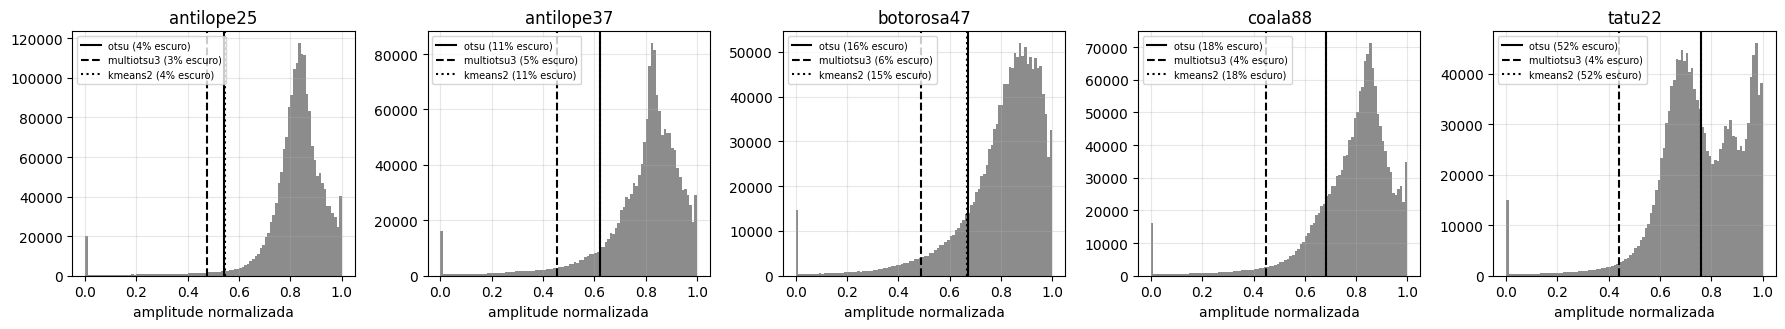

In [5]:
# Desenhando o histograma da amplitude normalizada de cada poço com os limiares de Otsu, Multi-Otsu e K-means
estilos = {"otsu": "-", "multiotsu3": "--", "kmeans2": ":"}
fig, eixos = plt.subplots(1, 5, figsize=(18, 3.4), sharey=False)
for ax, p in zip(eixos, POCOS):
    v = np.asarray(norm[p][~excl[p]][::10], dtype=np.float32).ravel()
    ax.hist(v, bins=100, range=(0, 1), color="0.55")
    r = tab[tab.poco == p].iloc[0]
    for k, ls in estilos.items():
        ax.axvline(r[f"lim_{k}"], color="k", ls=ls, lw=1.5, label=f"{k} ({r[f'frac_{k}']:.0%} escuro)")
    ax.set_title(p)
    ax.set_xlabel("amplitude normalizada")
    ax.legend(fontsize=7, loc="upper left")
    del v
fig.tight_layout()
fig.savefig(f"{PASTA}/histogramas_normalizados.png", dpi=150)
plt.show()

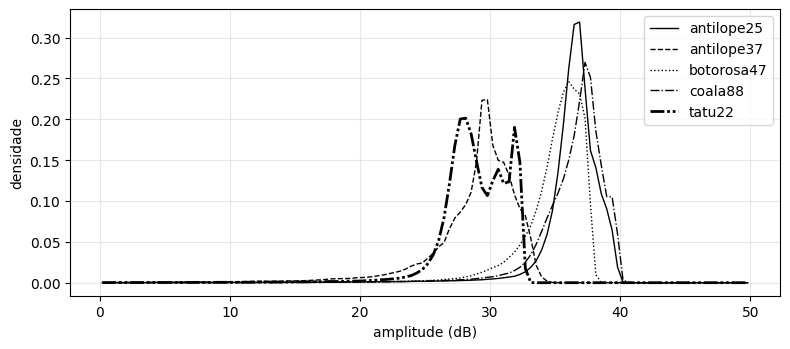

In [6]:
# Desenhando o histograma em dB dos cinco poços, com estilos de linha diferentes (válido para impressão em cinza)
fig, ax = plt.subplots(figsize=(8, 3.6))
for p, ls in zip(POCOS, ["-", "--", ":", "-.", (0, (5, 1, 1, 1, 1, 1))]):
    db = brutas[p][~excl[p]][::10].ravel()
    h, b = np.histogram(db, bins=120, range=(0, 50), density=True)
    ax.plot(0.5 * (b[1:] + b[:-1]), h, color="k", ls=ls, lw=2 if p == POCO else 1, label=p)
    del db
ax.set_xlabel("amplitude (dB)")
ax.set_ylabel("densidade")
ax.legend()
fig.tight_layout()
fig.savefig(f"{PASTA}/histogramas_db.png", dpi=150)
plt.show()

### 6.5 Fração escura ao longo da profundidade
Fração de pixels escuros em cada patch válido, por profundidade (tatu22) e por poço (distribuição).

In [7]:
# Calculando a fração escura de cada patch válido de todos os poços (limiar de Otsu da referência)
indice = pd.read_csv(f"{CARAC_DIR}/patches_indice.csv")
partes = []
for p in POCOS:
    g = indice[indice.poco == p].copy()
    g["frac_escura"] = fracao_escura(NPY_DIR, p, g.linha_ini.values, LIMIARES[p], ALTURA_PATCH)
    partes.append(g)
indice = pd.concat(partes, ignore_index=True)
print(indice.groupby("poco").frac_escura.describe().round(3).to_string())
print("\nPatches com mais de 50% de pixels escuros:")
print(indice.assign(acima=indice.frac_escura > 0.5).groupby("poco").acima.agg(["sum", "mean"]).round(3).to_string())
indice.to_csv(f"{PASTA}/fracao_escura_por_patch.csv", index=False)

            count   mean    std    min    25%    50%    75%    max
poco                                                              
antilope25  849.0  0.035  0.068  0.000  0.003  0.011  0.037  0.683
antilope37  676.0  0.105  0.170  0.000  0.007  0.039  0.129  0.979
botorosa47  617.0  0.155  0.157  0.000  0.028  0.101  0.235  0.747
coala88     684.0  0.183  0.196  0.000  0.013  0.105  0.306  0.771
tatu22      639.0  0.523  0.419  0.001  0.022  0.684  0.946  1.000

Patches com mais de 50% de pixels escuros:
            sum   mean
poco                  
antilope25    3  0.004
antilope37   25  0.037
botorosa47   26  0.042
coala88      61  0.089
tatu22      361  0.565


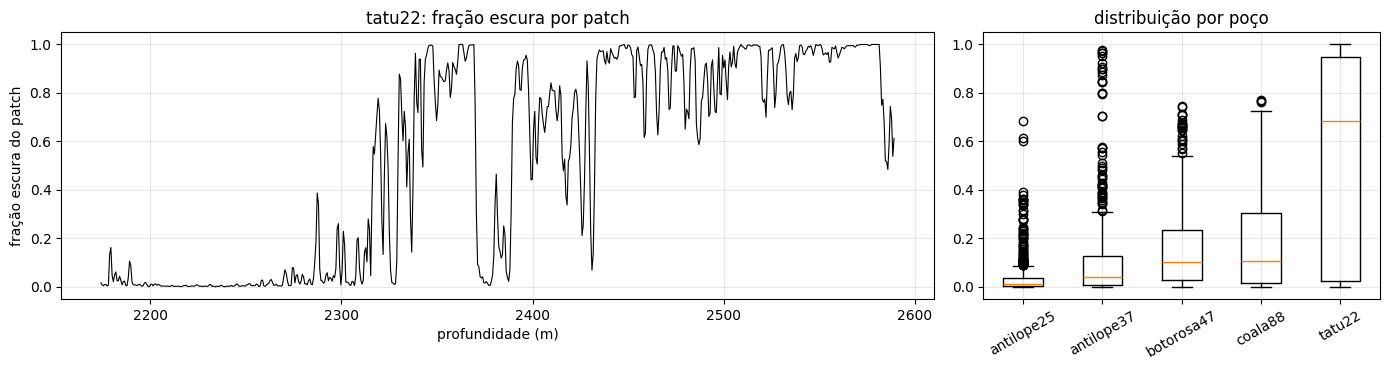

In [8]:
# Desenhando a fração escura do tatu22 ao longo da profundidade e a distribuição por poço
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
g = indice[indice.poco == POCO]
a1.plot(g.prof_ini_m, g.frac_escura, color="k", lw=0.8)
a1.set_xlabel("profundidade (m)")
a1.set_ylabel("fração escura do patch")
a1.set_title(f"{POCO}: fração escura por patch")
a2.boxplot([indice[indice.poco == p].frac_escura for p in POCOS], tick_labels=POCOS)
a2.set_title("distribuição por poço")
a2.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(f"{PASTA}/fracao_escura_profundidade.png", dpi=150)
plt.show()

### 6.6 Patches do tatu22 com o pseudo-rótulo
Dois patches de menor fração escura, dois de fração mediana e dois de maior fração. Em cada um: a imagem (cinza; claro = eco forte) e o pseudo-rótulo (preto = escuro pelo limiar de Otsu).

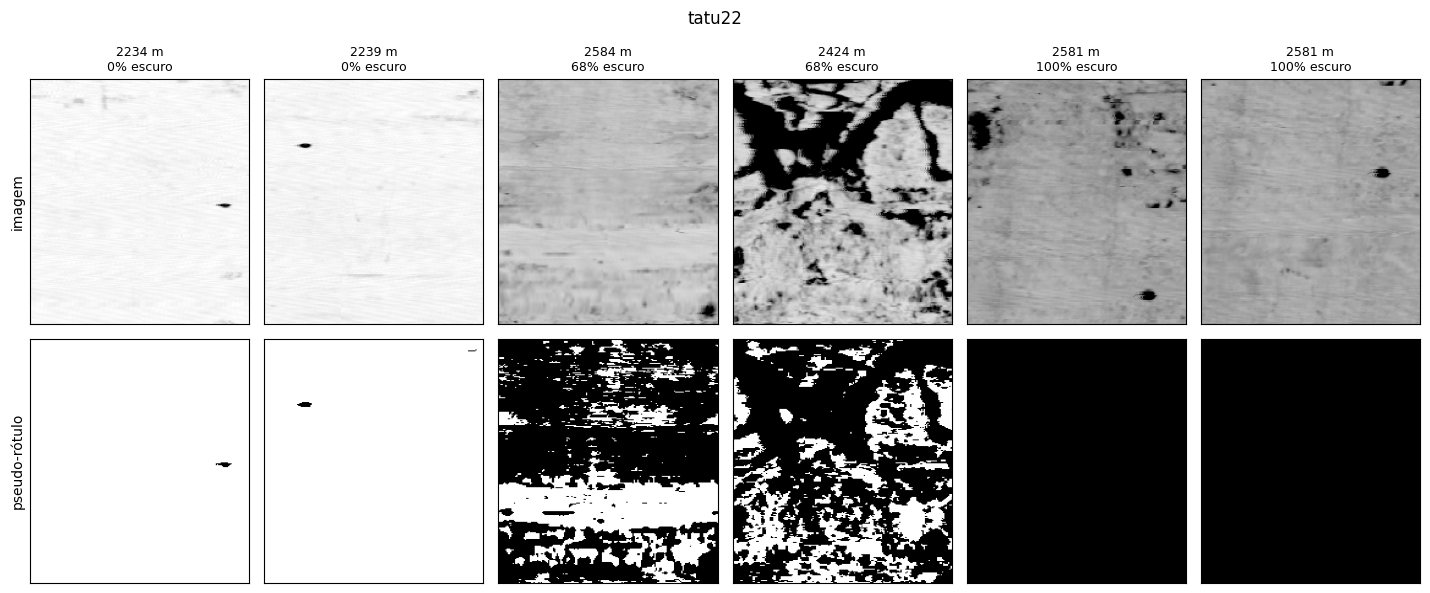

In [9]:
# Escolhendo os patches do tatu22 (2 menores, 2 medianos e 2 maiores frações escuras)
def escolher(poco, quantos=(2, 2, 2)):
    g = indice[indice.poco == poco].sort_values("frac_escura").reset_index(drop=True)
    meio = len(g) // 2
    return pd.concat([g.iloc[:quantos[0]], g.iloc[meio - quantos[1] // 2: meio - quantos[1] // 2 + quantos[1]],
                      g.iloc[len(g) - quantos[2]:]])

def desenhar(poco, sel, arquivo):
    fig, eixos = plt.subplots(2, len(sel), figsize=(2.4 * len(sel), 6))
    for j, (_, r) in enumerate(sel.iterrows()):
        x = np.asarray(norm[poco][int(r.linha_ini):int(r.linha_ini) + ALTURA_PATCH], dtype=np.float32)
        eixos[0, j].imshow(x, cmap="gray", vmin=0, vmax=1, aspect="auto")
        eixos[1, j].imshow(x < LIMIARES[poco], cmap="gray_r", vmin=0, vmax=1, aspect="auto")
        eixos[0, j].set_title(f"{r.prof_ini_m:.0f} m\n{r.frac_escura:.0%} escuro", fontsize=9)
        for ax in eixos[:, j]:
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
    eixos[0, 0].set_ylabel("imagem")
    eixos[1, 0].set_ylabel("pseudo-rótulo")
    fig.suptitle(poco)
    fig.tight_layout()
    fig.savefig(f"{PASTA}/{arquivo}", dpi=150)
    plt.show()

desenhar(POCO, escolher(POCO), "patches_tatu22.png")

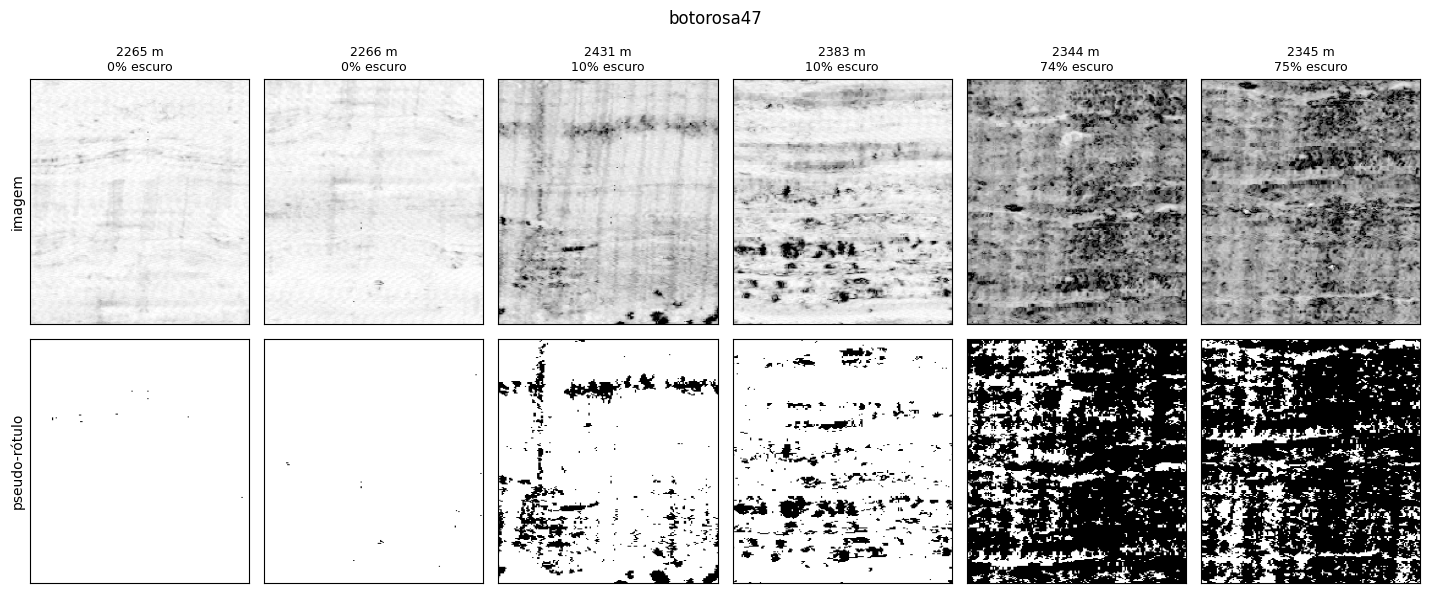

In [10]:
# Desenhando, para comparação, patches do poço de comparação (mesma regra de escolha)
desenhar(COMPARA, escolher(COMPARA), f"patches_{COMPARA}.png")